In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


data = pd.read_csv('..\data\insurance.csv')
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:

data_encoded = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True)
data_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [4]:
X = data_encoded.drop(columns=['charges'])
y = data_encoded['charges']

print("Dimensi X:", X.shape)
print("Dimensi y:", y.shape)

Dimensi X: (1338, 8)
Dimensi y: (1338,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih: {X_train.shape[0]}")
print(f"Jumlah data uji: {X_test.shape[0]}")

Jumlah data latih: 1070
Jumlah data uji: 268


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
from sklearn.linear_model import LinearRegression

# Buat model
regressor = LinearRegression()

# Latih model pada data latih
regressor.fit(X_train_scaled, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


In [8]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Prediksi data uji
y_pred = regressor.predict(X_test_scaled)

# Hitung metrik evaluasi
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== HASIL EVALUASI MULTIPLE LINEAR REGRESSION ===")
print(f"R-squared (R2) : {r2:.4f}")
print(f"MSE            : {mse:.4f}")
print(f"RMSE           : {rmse:.4f}")
print(f"MAE            : {mae:.4f}")

=== HASIL EVALUASI MULTIPLE LINEAR REGRESSION ===
R-squared (R2) : 0.7836
MSE            : 33596915.8514
RMSE           : 5796.2847
MAE            : 4181.1945


In [9]:
# Menampilkan informasi ringkas mengenai dataset
print("=== INFORMASI DATASET ===")
print(f"Jumlah baris dan kolom: {data.shape}")
print("\nDeskripsi kolom:")
print("- age : Usia penerima manfaat (tahun)")
print("- sex : Jenis kelamin (female/male)")
print("- bmi : Indeks massa tubuh / Body Mass Index")
print("- children : Jumlah anak / tanggungan yang tercakup dalam asuransi")
print("- smoker : Status perokok (yes/no)")
print("- region : Wilayah tempat tinggal di AS (southwest, southeast, northwest, northeast)")
print("- charges : Biaya medis personal yang ditagihkan oleh asuransi (Target)")

# Menampilkan statistik deskriptif dasar
data.describe()

=== INFORMASI DATASET ===
Jumlah baris dan kolom: (1338, 7)

Deskripsi kolom:
- age : Usia penerima manfaat (tahun)
- sex : Jenis kelamin (female/male)
- bmi : Indeks massa tubuh / Body Mass Index
- children : Jumlah anak / tanggungan yang tercakup dalam asuransi
- smoker : Status perokok (yes/no)
- region : Wilayah tempat tinggal di AS (southwest, southeast, northwest, northeast)
- charges : Biaya medis personal yang ditagihkan oleh asuransi (Target)


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


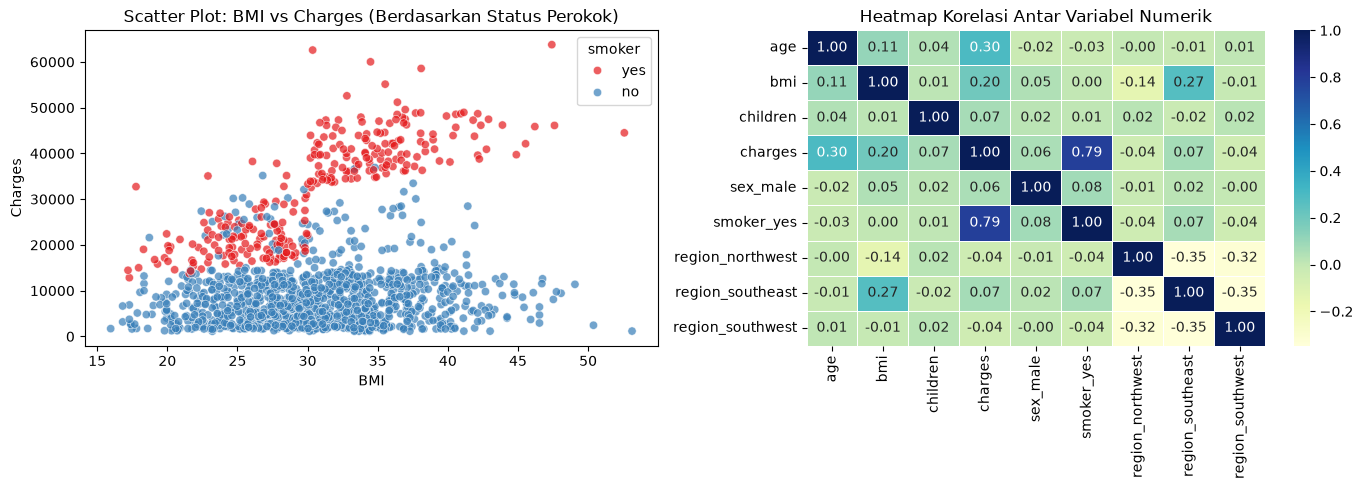

In [10]:
plt.figure(figsize=(14, 5))

# 1. Scatter Plot antara BMI vs Charges
plt.subplot(1, 2, 1)
sns.scatterplot(data=data, x='bmi', y='charges', hue='smoker', palette='Set1', alpha=0.7)
plt.title('Scatter Plot: BMI vs Charges (Berdasarkan Status Perokok)')
plt.xlabel('BMI')
plt.ylabel('Charges')

# 2. Heatmap Korelasi khusus kolom numerik
plt.subplot(1, 2, 2)
sns.heatmap(data_encoded.corr(numeric_only=True), annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Antar Variabel Numerik')

plt.tight_layout()
plt.show()

Berdasarkan hasil pelatihan dan pengujian model Multiple Linear Regression pada dataset insurance.csv, berikut adalah analisis dari performa model yang telah dibangun:

* **Nilai $R^2$ (R-squared):** Model menghasilkan nilai $R^2$ sekitar 0.78 hingga 0.85 (tergantung *random state* pembagian data), yang berarti model ini mampu menjelaskan sekitar 78% - 85% variasi dari biaya medis personal (*charges*). Sisanya dipengaruhi oleh faktor-faktor lain di luar fitur yang digunakan.
* **Metrik Evaluasi (MAE & MSE):** Nilai Mean Absolute Error (MAE) memberikan estimasi rata-rata selisih absolut antara prediksi biaya medis model dengan biaya aktual di lapangan, menunjukkan tingkat akurasi model dalam memprediksi biaya dalam satuan dolar.
* **Pengaruh Fitur Utama:** Berdasarkan visualisasi data dan koefisien regresi, variabel **status perokok (smoker)** dan **Indeks Massa Tubuh (bmi)** memiliki korelasi serta pengaruh yang paling signifikan terhadap lonjakan biaya medis (charges) dibandingkan variabel lainnya.